In [1]:
import sys

print(sys.executable)
print(sys.version)

c:\Users\academytraining\Downloads\SIMS_Full_Workspace\.venv\Scripts\python.exe
3.13.17 (tags/v3.13.17:64e080d, Oct 21 2026, 14:08:53) [MSC v.1944 64 bit (AMD64)]


In [2]:
import pandas as pd

df = pd.read_csv(r"D:\62-DS\HousePrice Pred\house_pred_modified_data.csv")

print(df.head())
print("\nColumns:")
print(df.columns.tolist())

print("\nShape:")
print(df.shape)

         date      price  bedrooms  bathrooms  sqft_living  sqft_lot  floors  \
0  2014-05-02   313000.0       3.0       1.50         1340      7912     1.5   
1  2014-05-02  2384000.0       5.0       2.50         3650      9050     2.0   
2  2014-05-02   342000.0       3.0       2.00         1930     11947     1.0   
3  2014-05-02   420000.0       3.0       2.25         2000      8030     1.0   
4  2014-05-02   550000.0       4.0       2.50         1940     10500     1.0   

   waterfront  view  condition  sqft_above  sqft_basement  yr_built  \
0           0     0          3        1340              0      1955   
1           0     4          5        3370            280      1921   
2           0     0          4        1930              0      1966   
3           0     0          4        1000           1000      1963   
4           0     0          4        1140            800      1976   

   yr_renovated                    street       city  statezip  price_per_sqft  
0          

First 5 rows:
         date      price  bedrooms  bathrooms  sqft_living  sqft_lot  floors  \
0  2014-05-02   313000.0       3.0       1.50         1340      7912     1.5   
1  2014-05-02  2384000.0       5.0       2.50         3650      9050     2.0   
2  2014-05-02   342000.0       3.0       2.00         1930     11947     1.0   
3  2014-05-02   420000.0       3.0       2.25         2000      8030     1.0   
4  2014-05-02   550000.0       4.0       2.50         1940     10500     1.0   

   waterfront  view  condition  sqft_above  sqft_basement  yr_built  \
0           0     0          3        1340              0      1955   
1           0     4          5        3370            280      1921   
2           0     0          4        1930              0      1966   
3           0     0          4        1000           1000      1963   
4           0     0          4        1140            800      1976   

   yr_renovated                    street       city  statezip  price_per_sqft

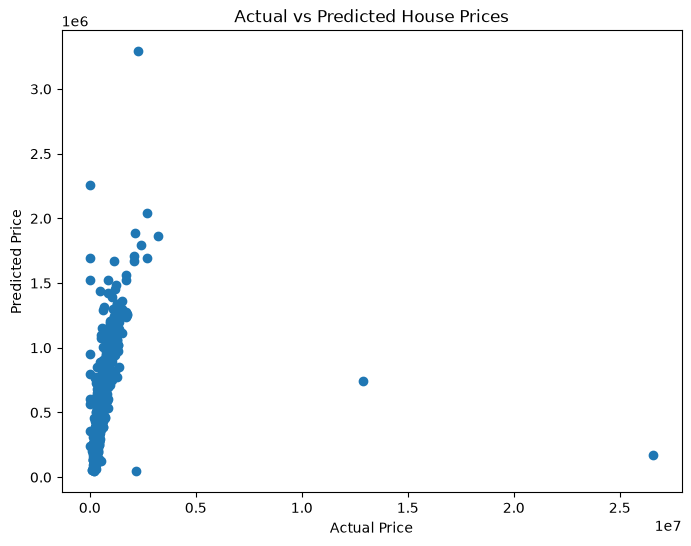

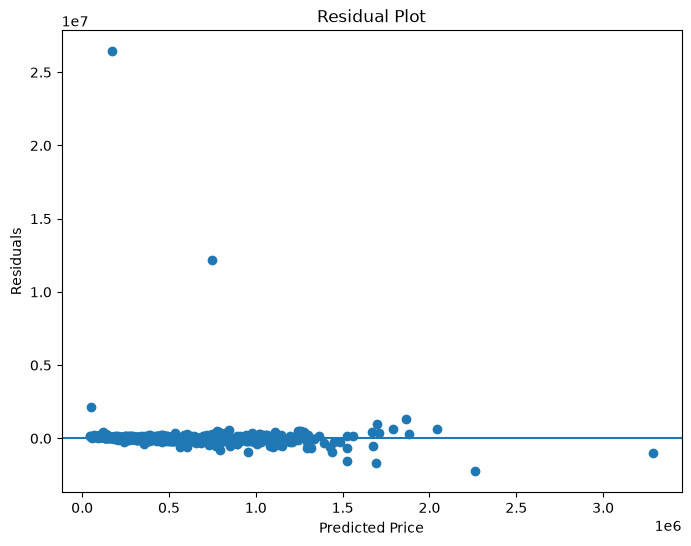

In [3]:
# 1. Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# 2. Load dataset

file_path = r"D:\62-DS\HousePrice Pred\house_pred_modified_data.csv"

df = pd.read_csv(file_path)


# 3. Display basic information

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())


# 4. Remove duplicate rows

df = df.drop_duplicates()


# 5. Convert date into useful numerical features

df['date'] = pd.to_datetime(df['date'])

df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month

df = df.drop('date', axis=1)


# 6. Drop columns that are not needed

# price_per_sqft is derived from price, so using it would cause data leakage
df = df.drop('price_per_sqft', axis=1)

# street has many unique values and is not useful for this basic model
df = df.drop('street', axis=1)


# 7. Convert categorical columns into numerical columns

df = pd.get_dummies(
    df,
    columns=['city', 'statezip'],
    drop_first=True
)


# 8. Separate input and target

X = df.drop('price', axis=1)
y = df['price']


# 9. Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)


print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)


# 10. Create Linear Regression model

model = LinearRegression()


# 11. Train the model

model.fit(X_train, y_train)


# 12. Make predictions

y_pred = model.predict(X_test)


# 13. Evaluate the model

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)


print("\n--- Linear Regression Results ---")
print("MAE  :", mae)
print("MSE  :", mse)
print("RMSE :", rmse)
print("R² Score:", r2)


# 14. Actual vs Predicted values

result = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print("\nActual vs Predicted:")
print(result.head(10))


# 15. Plot Actual vs Predicted

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

plt.show()


# 16. Residual Plot

residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals)

plt.axhline(y=0)

plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

In [4]:
print("Minimum price:", df['price'].min())
print("Maximum price:", df['price'].max())

print("\nZero prices:")
print((df['price'] == 0).sum())

print("\nMissing prices:")
print(df['price'].isnull().sum())

print("\nPrice statistics:")
print(df['price'].describe())

Minimum price: 0.0
Maximum price: 26590000.0

Zero prices:
49

Missing prices:
0

Price statistics:
count    4.600000e+03
mean     5.519630e+05
std      5.638347e+05
min      0.000000e+00
25%      3.228750e+05
50%      4.609435e+05
75%      6.549625e+05
max      2.659000e+07
Name: price, dtype: float64


Original shape: (4600, 18)
Shape after removing zero prices: (4551, 18)
Training Data: (3640, 133)
Testing Data: (911, 133)

--- Linear Regression Results ---
MAE : 121974.93634321149
MSE : 45122670693.94194
RMSE: 212420.97517416198
R² Score: 0.6966958916499055

Actual vs Predicted:
   Actual Price  Predicted Price
0     1225000.0     1.279594e+06
1      496752.0     5.683840e+05
2      612500.0     5.553642e+05
3      265000.0     2.531880e+05
4      615000.0     6.260828e+05
5      432000.0     4.056048e+05
6      305000.0     3.076427e+05
7      405000.0     2.888612e+05
8      349000.0     4.499450e+05
9      839000.0     8.578319e+05


C:\Users\academytraining\AppData\Local\Temp\ipykernel_9512\2124707779.py:34: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop('date', axis=1, inplace=True)
C:\Users\academytraining\AppData\Local\Temp\ipykernel_9512\2124707779.py:39: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(['street', 'price_per_sqft'], axis=1, inplace=True)


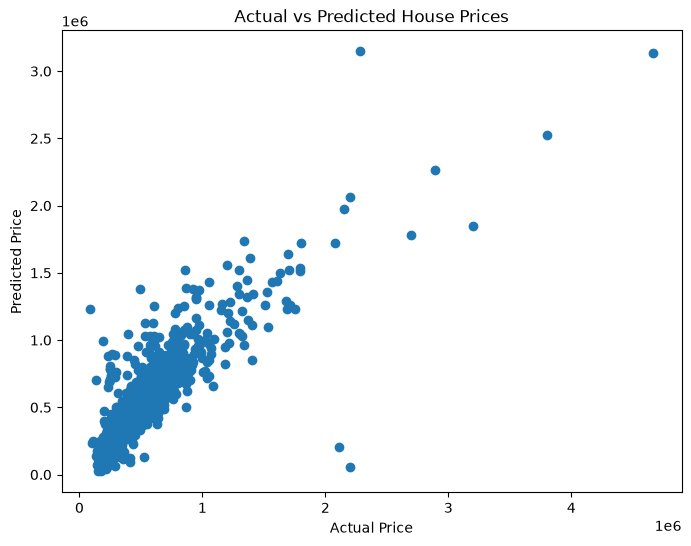

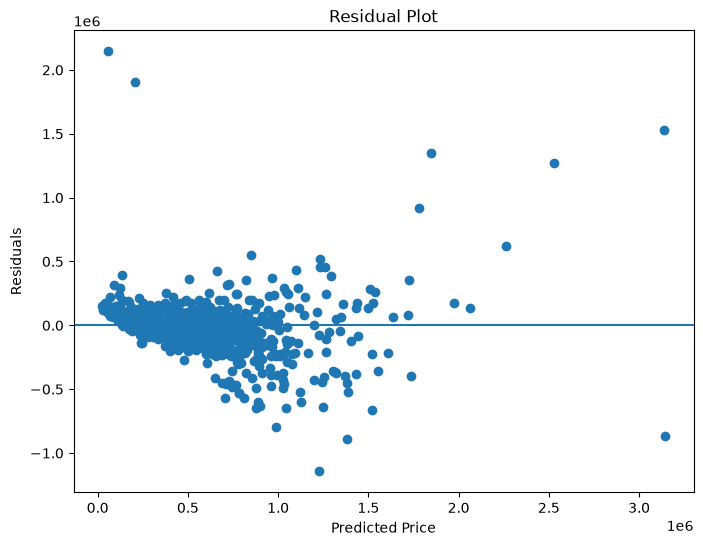

In [5]:
#NEWWWWWWWWWWWWW
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# 1. Load dataset

file_path = r"D:\62-DS\HousePrice Pred\house_pred_modified_data.csv"

df = pd.read_csv(file_path)

print("Original shape:", df.shape)


# 2. Remove rows with zero price

df = df[df['price'] > 0].copy()

print("Shape after removing zero prices:", df.shape)


# 3. Convert date into useful features

df['date'] = pd.to_datetime(df['date'])

df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month

df.drop('date', axis=1, inplace=True)


# 4. Remove columns not suitable for this model

df.drop(['street', 'price_per_sqft'], axis=1, inplace=True)


# 5. Convert categorical columns to numerical form

df = pd.get_dummies(
    df,
    columns=['city', 'statezip'],
    drop_first=True
)


# 6. Separate input and target

X = df.drop('price', axis=1)
y = df['price']


# 7. Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


# 8. Create Linear Regression model

model = LinearRegression()


# 9. Train model

model.fit(X_train, y_train)


# 10. Prediction

y_pred = model.predict(X_test)


# 11. Evaluation

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n--- Linear Regression Results ---")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R² Score:", r2)


# 12. Actual vs Predicted

result = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print("\nActual vs Predicted:")
print(result.head(10))


# 13. Actual vs Predicted graph

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

plt.show()


# 14. Residual plot

residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals)

plt.axhline(0)

plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()